# BROWNIANO 1 — ¿el movimiento es browniano?

Grabación `C:\datos_pinzas\GRABACIONES\BROWNIANO 1` (ThorCam, 31 TIFF, 5102 cuadros de 1280 × 1024). Las trayectorias salen de `TouchDesigner/bloques/_lote.py` con los **parámetros por defecto** de los bloques y están en `datos/BROWNIANO 1/`.

Para que un movimiento sea browniano tienen que pasar tres cosas, y este notebook mira las tres:

1. el MSD crece **lineal** con el retardo: $\mathrm{MSD}(\tau) = 4D\tau + 4\sigma^2$;
2. los desplazamientos a un retardo fijo son **gaussianos**, con media cero e iguales en $x$ y en $y$;
3. un paso **no depende** del anterior.

Dos límites de los datos:

- **Tiempo nominal.** Los TIFF no traen el tiempo de cada cuadro. Se usó 10.02 cuadros por segundo, estimado con las fechas de los archivos.
- **Sin escala.** Todo está en px del sensor; falta la retícula para pasar a µm.

In [1]:
from trayectorias import *
from scipy import stats

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE = "#2A9D8F", "#E76F51", "#264653"

DATOS = os.path.join(RAIZ, "datos", "BROWNIANO 1")        # RAIZ = pinzas ópticas/
FIGURAS = os.path.join(RAIZ, "figuras", "BROWNIANO 1")
os.makedirs(FIGURAS, exist_ok=True)

LARGO_MIN = 300      # cuadros medidos (30 s): las trayectorias más cortas no entran
MAX_LAG = 30         # retardo máximo del MSD, en cuadros (3 s)
N_AJUSTE = 4         # retardos que se usan para ajustar D
ALFA_LIBRE = 0.5     # pendiente log-log del MSD por encima de la cual una partícula es libre
VENTANA = 101        # pasos (10 s) con los que se calcula la sigma local


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)


datos = cargar(DATOS)
tr = datos["tr"]
n_total, n_colision = len(tr), int(tr.colision.sum())
tr.loc[tr.colision == 1, ["x_px", "y_px"]] = np.nan       # dos beads muy cerca: posición poco confiable
t, X, Y, ids, u = matrices(datos, largo_min=LARGO_MIN)
print("%d cuadros, %.0f s | %d trayectorias en total, %d con más de %d cuadros | unidad: %s"
      % (len(t), t[-1] - t[0], tr.particula.nunique(), len(ids), LARGO_MIN, u))
print("puntos descartados por colisión: %d de %d" % (n_colision, n_total))

5102 cuadros, 509 s | 43 trayectorias en total, 11 con más de 300 cuadros | unidad: px
puntos descartados por colisión: 3048 de 17794


## 1. Trayectorias, deriva y MSD de cada una

Las partículas se corren a velocidades distintas (flujo en la muestra), así que a cada una se le resta **su** recta $x(t)$, $y(t)$ antes de calcular el MSD. $\alpha$ es la pendiente del MSD en log-log: cerca de 1 es difusión libre, por debajo de 0.5 la partícula está confinada o pegada.

In [2]:
Xs, Ys = sin_deriva_por_particula(t, X, Y)
vx, vy = velocidades(t, X, Y)
m = msd(t, Xs, Ys, MAX_LAG)
alfa = pendiente_loglog(m)
tabla = coeficientes_D(m, n_puntos=N_AJUSTE)
libres = alfa > ALFA_LIBRE
tabla = pd.DataFrame({"partícula": ids, "cuadros": np.isfinite(X).sum(0), "deriva [px/s]": np.hypot(vx, vy),
                      "alfa": alfa, "D [px²/s]": tabla.D.values, "sigma [px]": tabla.sigma.values,
                      "libre": libres})
print("libres: %d | confinadas: %d (partícula %s)"
      % (libres.sum(), (~libres).sum(), ", ".join(map(str, ids[~libres])) or "-"))
tabla.round(2)

libres: 10 | confinadas: 1 (partícula 3)


,partícula,cuadros,deriva [px/s],alfa,D [px²/s],sigma [px],libre
0,0,757,1.30,0.79,5.48,0.21,True
1,1,1842,1.95,1.08,6.62,0.31,True
2,2,3122,1.84,1.04,6.51,0.20,True
3,3,647,0.01,0.34,1.34,0.55,False
4,6,3549,0.89,0.95,3.52,0.54,True
5,7,684,4.74,0.99,13.47,0.79,True
6,24,376,7.33,0.90,11.48,1.09,True
7,26,450,7.54,1.17,10.85,0.87,True
8,27,352,7.55,0.97,9.74,0.97,True
9,40,341,3.80,0.76,2.93,1.27,True


## 2. MSD

Promedio de las trayectorias libres, pesado por la cantidad de pares de cada una. La barra de error es la dispersión entre trayectorias dividida por $\sqrt{N}$. La recta se ajusta a los primeros `N_AJUSTE` retardos (puntos llenos) y se extiende al resto (puntos huecos).

MSD del conjunto: D = 6.21 px²/s, ordenada = 1.34 px² (sigma = 0.58 px)
pendiente log-log del MSD del conjunto (30 retardos): 0.93
recta extendida vs medido en tau = 3.0 s: 75.7 vs 82.2 px² (+9 %)
D por trayectoria: de 2.9 a 13.5 px²/s, media 7.5 ± 1.2 (dispersión/√N)


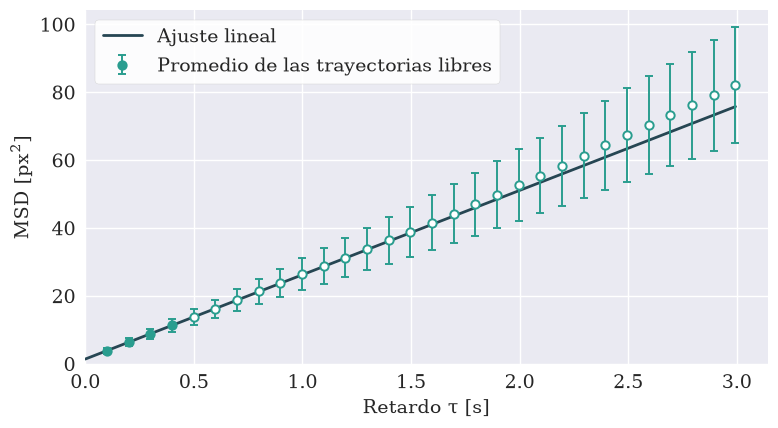

In [3]:
ml = columnas(m, libres)
prom, err = msd_conjunto(ml)
tau = m["tau"]
aj = libre.ajustar_msd(tau, prom, 0.0, n_puntos=N_AJUSTE)
pend_loglog = np.polyfit(np.log(tau), np.log(prom), 1)[0]
D_ind = tabla["D [px²/s]"][libres]

fig, ax = plt.subplots(figsize=(8, 4.5))
estilo = dict(fmt="o", ms=6, capsize=3, elinewidth=1.4, capthick=1.4, mew=1.4, color=SERIE1, mec=SERIE1, zorder=3)
ax.errorbar(tau[:N_AJUSTE], prom[:N_AJUSTE], err[:N_AJUSTE], mfc=SERIE1, label="Promedio de las trayectorias libres", **estilo)
ax.errorbar(tau[N_AJUSTE:], prom[N_AJUSTE:], err[N_AJUSTE:], mfc="white", **estilo)
tt = np.linspace(0, tau[-1], 100)
ax.plot(tt, 4 * aj["D"] * tt + aj["ordenada"], color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal")
ax.set_xlabel(r"Retardo $\tau$ [s]")
ax.set_ylabel(r"MSD [px$^2$]")
ax.set_xlim(0, None); ax.set_ylim(0, None)
ax.legend(loc="upper left", facecolor="white", framealpha=0.9)
guardar(fig, "msd")

print("MSD del conjunto: D = %.2f px²/s, ordenada = %.2f px² (sigma = %.2f px)" % (aj["D"], aj["ordenada"], aj["sigma"]))
print("pendiente log-log del MSD del conjunto (30 retardos): %.2f" % pend_loglog)
print("recta extendida vs medido en tau = %.1f s: %.1f vs %.1f px² (%+.0f %%)"
      % (tau[-1], 4 * aj["D"] * tau[-1] + aj["ordenada"], prom[-1],
         100 * (prom[-1] / (4 * aj["D"] * tau[-1] + aj["ordenada"]) - 1)))
print("D por trayectoria: de %.1f a %.1f px²/s, media %.1f ± %.1f (dispersión/√N)"
      % (D_ind.min(), D_ind.max(), D_ind.mean(), D_ind.std() / np.sqrt(len(D_ind))))

## 3. Histograma de desplazamientos

Desplazamientos entre cuadros consecutivos ($\tau$ = 0.1 s) de las trayectorias libres. Cada trayectoria tiene su propio $D$, así que cada desplazamiento se divide por la desviación estándar $\sigma$ de su trayectoria y de su eje antes de juntarlos; si no, mezclar partículas con $D$ distinto da colas anchas aunque cada una sea gaussiana.

11690 desplazamientos en x y 11690 en y, de 10 trayectorias
sigma por paso: de 1.00 a 2.24 px según la trayectoria
media del paso / sigma: como mucho 0.030 (cero = sin deriva restante)
sigma_y / sigma_x por trayectoria: 0.97 ± 0.10 (1 = isótropo)


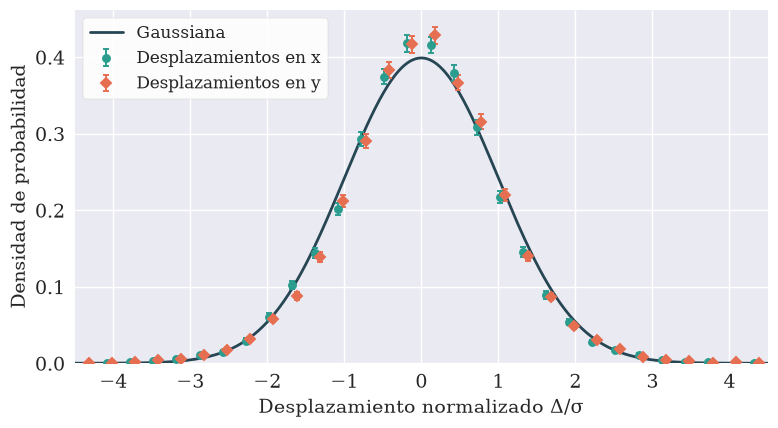

In [4]:
def pasos_normalizados(A, local=False):
    # pasos de un cuadro de cada trayectoria libre, divididos por su sigma (de toda la trayectoria o local)
    salida = []
    for k in np.flatnonzero(libres):
        d = A[1:, k] - A[:-1, k]
        d = d[np.isfinite(d)]
        s = pd.Series(d).rolling(VENTANA, center=True, min_periods=VENTANA // 3).std().values if local else d.std()
        salida.append(d / s)
    z = np.concatenate(salida)
    return z[np.isfinite(z)]


def densidad(z, bordes):
    # histograma normalizado: centros, densidad y su error (raíz de las cuentas); sin los bins vacíos
    n, _ = np.histogram(z, bordes)
    ancho = np.diff(bordes)
    ok = n > 0
    return (0.5 * (bordes[1:] + bordes[:-1]))[ok], (n / (len(z) * ancho))[ok], (np.sqrt(n) / (len(z) * ancho))[ok]


zx, zy = pasos_normalizados(Xs), pasos_normalizados(Ys)
u_ = np.linspace(-5.6, 5.6, 400)
gauss = np.exp(-u_ ** 2 / 2) / np.sqrt(2 * np.pi)

fig, ax = plt.subplots(figsize=(8, 4.5))
bordes = np.arange(-4.5, 4.51, 0.3)
marca = dict(ms=5, capsize=2, elinewidth=1.4, capthick=1.4, mew=1.4, zorder=3)
for z, color, fmt, corr, nombre in ((zx, SERIE1, "o", -0.03, "Desplazamientos en $x$"), (zy, SERIE2, "D", 0.03, "Desplazamientos en $y$")):
    cx, dens, e = densidad(z, bordes)
    ax.errorbar(cx + corr, dens, e, fmt=fmt, color=color, mfc=color, mec=color, label=nombre, **marca)
ax.plot(u_, gauss, color=AJUSTE, lw=2, zorder=2, label="Gaussiana")
ax.set_xlabel(r"Desplazamiento normalizado $\Delta/\sigma$")
ax.set_ylabel("Densidad de probabilidad")
ax.set_xlim(-4.5, 4.5); ax.set_ylim(0, None)
ax.legend(loc="upper left", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "histograma_desplazamientos")

sx = np.array([np.nanstd(np.diff(Xs[:, k])) for k in np.flatnonzero(libres)])
sy = np.array([np.nanstd(np.diff(Ys[:, k])) for k in np.flatnonzero(libres)])
mx = np.array([np.nanmean(np.diff(Xs[:, k])) for k in np.flatnonzero(libres)])
my = np.array([np.nanmean(np.diff(Ys[:, k])) for k in np.flatnonzero(libres)])
print("%d desplazamientos en x y %d en y, de %d trayectorias" % (len(zx), len(zy), libres.sum()))
print("sigma por paso: de %.2f a %.2f px según la trayectoria" % (min(sx.min(), sy.min()), max(sx.max(), sy.max())))
print("media del paso / sigma: como mucho %.3f (cero = sin deriva restante)" % np.max(np.abs(np.r_[mx / sx, my / sy])))
print("sigma_y / sigma_x por trayectoria: %.2f ± %.2f (1 = isótropo)" % ((sy / sx).mean(), (sy / sx).std()))

### Las colas

En escala lineal las colas no se ven. En escala logarítmica una gaussiana es una parábola, y cualquier exceso en las colas queda a la vista. Acá se juntan $x$ e $y$ y se comparan dos formas de normalizar: con la $\sigma$ de **toda** la trayectoria, y con la $\sigma$ **local** (la de los `VENTANA` pasos de alrededor, 10 s).

gaussiana: curtosis en exceso 0, |z| > 3 en 0.27 %, |z| > 4 en 0.006 %
(dividir por una sigma de 101 pasos baja la curtosis en 0.06 aunque el dato sea gaussiano)


,normalización,n,curtosis en exceso,error,|z| > 3 [%],|z| > 4 [%],p de KS
0,sin normalizar (px),23380,1.8982,0.032,1.0265,0.2908,0.0000
1,sigma de toda la trayectoria,23380,0.6317,0.032,0.6116,0.0813,0.0000
2,sigma local,23380,0.0150,0.032,0.2908,0.0043,0.6166


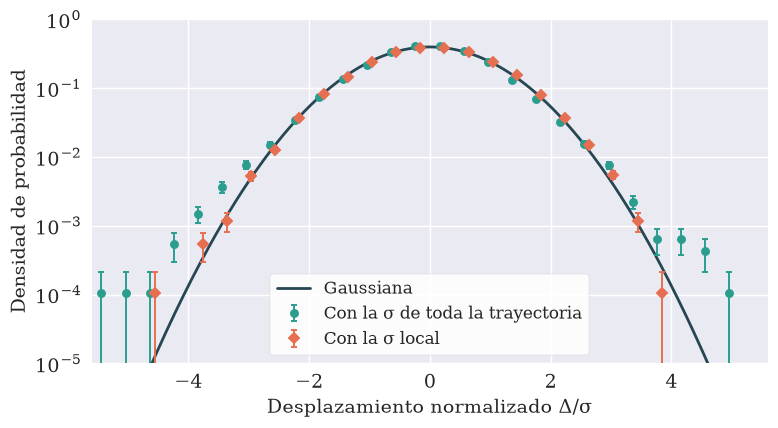

In [5]:
z_tray = np.r_[zx, zy]
z_local = np.r_[pasos_normalizados(Xs, local=True), pasos_normalizados(Ys, local=True)]
crudo = libre.desplazamientos(t, Xs[:, libres], Ys[:, libres], 1, libre.periodo_nominal(t))

fig, ax = plt.subplots(figsize=(8, 4.5))
bordes = np.arange(-5.6, 5.61, 0.4)
for z, color, fmt, corr, nombre in ((z_tray, SERIE1, "o", -0.04, r"Con la $\sigma$ de toda la trayectoria"),
                                    (z_local, SERIE2, "D", 0.04, r"Con la $\sigma$ local")):
    cx, dens, e = densidad(z, bordes)
    ax.errorbar(cx + corr, dens, e, fmt=fmt, color=color, mfc=color, mec=color, label=nombre, **marca)
ax.plot(u_, gauss, color=AJUSTE, lw=2, zorder=2, label="Gaussiana")
ax.set_yscale("log")
ax.set_xlabel(r"Desplazamiento normalizado $\Delta/\sigma$")
ax.set_ylabel("Densidad de probabilidad")
ax.set_xlim(-5.6, 5.6); ax.set_ylim(1e-5, 1)
ax.legend(loc="lower center", fontsize=12, facecolor="white", framealpha=0.9)
guardar(fig, "histograma_desplazamientos_log")

filas = []
for nombre, z in (("sin normalizar (px)", crudo / crudo.std()), ("sigma de toda la trayectoria", z_tray), ("sigma local", z_local)):
    filas.append({"normalización": nombre, "n": len(z), "curtosis en exceso": stats.kurtosis(z),
                  "error": np.sqrt(24 / len(z)), "|z| > 3 [%]": 100 * np.mean(np.abs(z) > 3),
                  "|z| > 4 [%]": 100 * np.mean(np.abs(z) > 4), "p de KS": stats.kstest(z / z.std(), "norm").pvalue})
print("gaussiana: curtosis en exceso 0, |z| > 3 en 0.27 %, |z| > 4 en 0.006 %")
print("(dividir por una sigma de %d pasos baja la curtosis en %.2f aunque el dato sea gaussiano)" % (VENTANA, 6 / (VENTANA + 1)))
pd.DataFrame(filas).round(4)

### Cuánto cambia el tamaño del paso a lo largo de una trayectoria

Si la $\sigma$ de los pasos cambia con el tiempo (la partícula sube o baja, se desenfoca), juntar toda la trayectoria mezcla gaussianas de distinto ancho. Eso es lo que da las colas de la curva verde.

In [6]:
filas = []
for k in np.flatnonzero(libres):
    d = np.diff(Xs[:, k]); d = d[np.isfinite(d)]
    s = pd.Series(d).rolling(VENTANA, center=True, min_periods=VENTANA // 3).std().dropna()
    filas.append({"partícula": ids[k], "sigma_x de toda la trayectoria [px]": d.std(),
                  "sigma_x local mínima [px]": s.min(), "sigma_x local máxima [px]": s.max(), "máx / mín": s.max() / s.min()})
pd.DataFrame(filas).round(2)

,partícula,sigma_x de toda la trayectoria [px],sigma_x local mínima [px],sigma_x local máxima [px],máx / mín
0,0,1.00,0.72,1.21,1.67
1,1,1.20,0.88,1.54,1.74
2,2,1.18,0.68,1.62,2.39
3,6,1.17,0.67,1.92,2.86
4,7,2.08,1.49,3.52,2.35
5,24,2.24,1.76,2.74,1.56
6,26,1.90,1.14,2.43,2.14
7,27,1.90,1.49,2.34,1.58
8,40,2.17,1.46,2.64,1.80
9,42,2.19,1.88,2.49,1.32


## 4. ¿Un paso depende del anterior?

En un browniano puro la correlación entre un paso y el siguiente es cero. El ruido de localización $\sigma$ la hace **negativa** (si una posición salió corrida, el paso siguiente la corrige): se espera $-\sigma^2 / (2D\tau + 2\sigma^2)$, con $D$ y $\sigma$ del ajuste del MSD de cada trayectoria.

Esta cuenta **no es una prueba independiente** del MSD: la correlación entre pasos y la ordenada del MSD son la misma información. Lo que muestra es que la anticorrelación tiene el tamaño que corresponde a esa ordenada. Para saber si esa ordenada es de verdad ruido de localización hace falta medirlo aparte; la partícula confinada, que casi no se mueve, da una cota.

In [7]:
dt = libre.periodo_nominal(t)
filas = []
for k in np.flatnonzero(libres):
    r = []
    for A in (Xs, Ys):
        d = np.diff(A[:, k])
        ok = np.isfinite(d[:-1]) & np.isfinite(d[1:])
        r.append(np.corrcoef(d[:-1][ok], d[1:][ok])[0, 1])
    D, s = tabla["D [px²/s]"][k], tabla["sigma [px]"][k]
    filas.append({"partícula": ids[k], "correlación medida": np.mean(r), "esperada por el ruido": -s ** 2 / (2 * D * dt + 2 * s ** 2),
                  "error": 1 / np.sqrt(ok.sum())})
corr = pd.DataFrame(filas)
dif = corr["correlación medida"] - corr["esperada por el ruido"]
print("diferencia medida − esperada: media %.3f, máxima %.3f" % (dif.mean(), dif.abs().max()))
for k in np.flatnonzero(~libres):       # si no se mueve, el paso es puro ruido: sigma = desvío del paso / raíz de 2
    print("partícula %d (confinada): ruido de localización como mucho %.2f px en x y %.2f px en y"
          % (ids[k], np.nanstd(np.diff(Xs[:, k])) / np.sqrt(2), np.nanstd(np.diff(Ys[:, k])) / np.sqrt(2)))
corr.round(3)

diferencia medida − esperada: media 0.007, máxima 0.040
partícula 3 (confinada): ruido de localización como mucho 0.58 px en x y 0.73 px en y


,partícula,correlación medida,esperada por el ruido,error
0,0,0.001,-0.039,0.037
1,1,-0.045,-0.065,0.023
2,2,-0.026,-0.030,0.018
3,6,-0.236,-0.225,0.017
4,7,-0.150,-0.159,0.039
5,24,-0.254,-0.254,0.052
6,26,-0.201,-0.207,0.048
7,27,-0.232,-0.245,0.054
8,40,-0.403,-0.423,0.056
9,42,-0.420,-0.387,0.057


## Conclusión

**Las partículas libres de esta grabación se mueven como un browniano**, montado sobre una deriva lenta de la muestra. Las tres condiciones se cumplen:

1. **MSD lineal.** El promedio de las 10 trayectorias libres sigue la recta ajustada en los primeros 0.4 s hasta los 3 s; a 3 s queda 9 % por encima, dentro de la barra de error. Del conjunto sale $D$ = 6.2 px²/s.
2. **Desplazamientos gaussianos.** Tienen media cero y el mismo ancho en $x$ y en $y$ ($\sigma_y/\sigma_x$ = 0.97 ± 0.10). Normalizados con la $\sigma$ de toda la trayectoria quedan colas algo más anchas que la gaussiana (curtosis en exceso 0.63 ± 0.03). Con la $\sigma$ local las colas desaparecen (0.02 ± 0.03, y 0.29 % de los pasos más allá de 3$\sigma$ contra 0.27 % de una gaussiana). El exceso viene de que el tamaño del paso cambia entre 1.3 y 2.9 veces a lo largo de una misma trayectoria, no de pasos que no sean gaussianos.
3. **Pasos sin memoria, salvo por el ruido.** La correlación entre pasos consecutivos va de 0.00 a −0.42 según la trayectoria, y coincide con la que da la ordenada del MSD si esa ordenada es ruido de localización.

Lo que este análisis **no** alcanza a decir:

- **Por qué $D$ cambia tanto entre trayectorias**: va de 2.9 a 13.5 px²/s. Las cuatro que derivan a más de 4.7 px/s tienen los $D$ más altos (9.7 a 13.5). Puede ser que estén a otra altura, pero no está medido.
- **Por qué cambia el tamaño del paso** dentro de una trayectoria.
- **Si $D$ es el que corresponde** al tamaño de las beads: sin escala no se puede comparar con Stokes–Einstein.
- **El valor de $D$ depende del fps**, que es una estimación (10.02): si el real es otro, $D$ cambia en la misma proporción.

Cuánto dato entró: de 43 trayectorias, 11 tienen más de 300 cuadros; una de esas (la 3) casi no se mueve y quedó afuera. Se descartaron 3048 de 17 794 puntos por colisión. Los parámetros de detección son los por defecto, sin ajustar a esta grabación.
